In [2]:

from google.colab import drive

drive.mount('/content/drive')
import pandas as pd
DATA_PATH = "/content/drive/MyDrive/polynomial.csv"
df = pd.read_csv(
    DATA_PATH
)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Position,Level,Salary
0,Business analyst,1,45000
1,Junior consultant,2,50000
2,Senior consultant,3,60000
3,Manager,4,80000
4,Country manager,5,110000


In [7]:
x = df.iloc[:, 1].values
x

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

In [9]:
y = df.iloc[:,2].values
y

array([  45000,   50000,   60000,   80000,  110000,  150000,  200000,
        300000,  500000, 1000000])

In [10]:
x = x.reshape(-1,1)

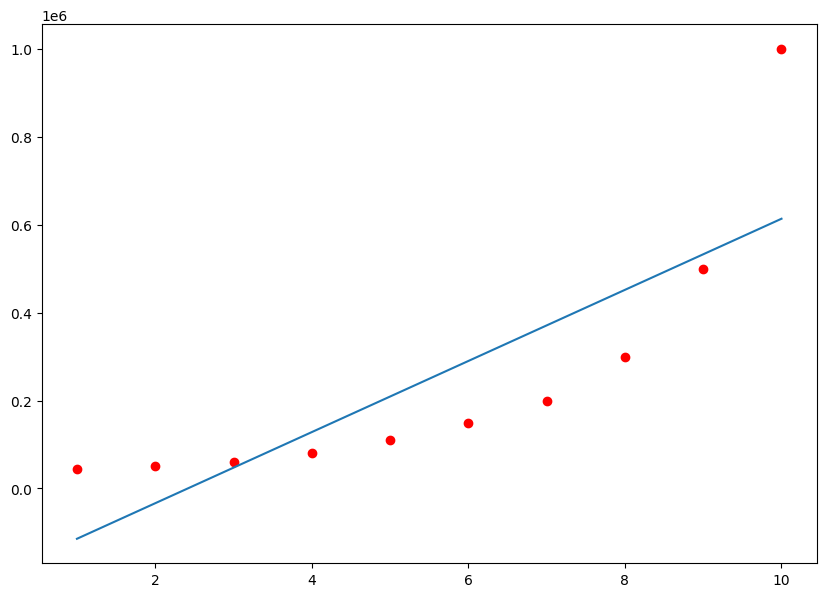

In [14]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

lin_reg = LinearRegression()
lin_reg.fit(x,y)

plt.figure(figsize=(10,7))
plt.scatter(x,y,color='red')
plt.plot(x,lin_reg.predict(x))

In [15]:
poly_reg2 = PolynomialFeatures(degree=2)
x_poly = poly_reg2.fit_transform(x)
x_poly

array([[  1.,   1.,   1.],
       [  1.,   2.,   4.],
       [  1.,   3.,   9.],
       [  1.,   4.,  16.],
       [  1.,   5.,  25.],
       [  1.,   6.,  36.],
       [  1.,   7.,  49.],
       [  1.,   8.,  64.],
       [  1.,   9.,  81.],
       [  1.,  10., 100.]])

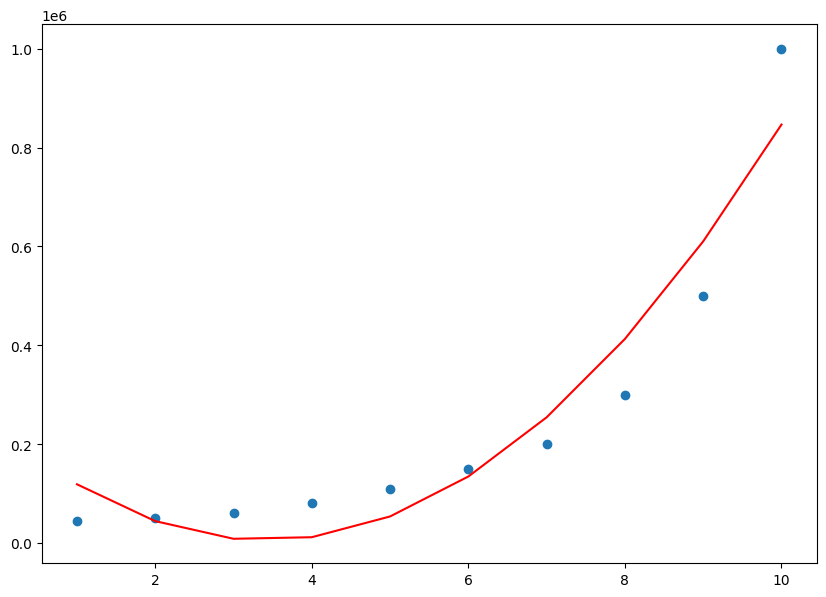

In [18]:
lin_reg2 = LinearRegression()
lin_reg2.fit(x_poly,y)

plt.figure(figsize=(10,7))
plt.scatter(x,y)
plt.plot(x,lin_reg2.predict(x_poly),color='red')

In [25]:
from sklearn.preprocessing import LabelEncoder
le_position = LabelEncoder()
df["pos"] = le_position.fit_transform(df['Position'])
df['pos']
x3 = df[['Level','pos']].values
x3


array([[ 1,  0],
       [ 2,  4],
       [ 3,  8],
       [ 4,  5],
       [ 5,  3],
       [ 6,  7],
       [ 7,  6],
       [ 8,  9],
       [ 9,  1],
       [10,  2]])

In [27]:
y3 = df['Salary'].values
y3

array([  45000,   50000,   60000,   80000,  110000,  150000,  200000,
        300000,  500000, 1000000])

In [28]:
lin_reg3 = LinearRegression()
lin_reg3.fit(x3,y3)

LinearRegression()

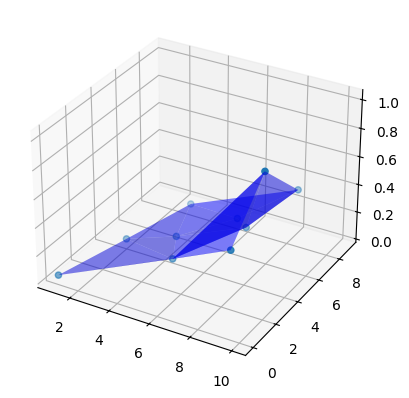

In [33]:
fig = plt.figure()
ax = fig.add_subplot(111,projection="3d")
ax.scatter(
    x3[:,0],
    x3[:,1],
    y3
)
ax.plot_trisurf(
    x3[:,0],
    x3[:,1],
    y3,
    alpha = 0.5,
    color="blue"
)